In [36]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as cx

In [14]:
# import data files
fl = gpd.read_file("fl_tes.geojson")
ma = gpd.read_file("ma_tes.geojson")
mn = gpd.read_file("mn_tes.geojson")
tx = gpd.read_file("tx_tes.geojson")
wa = gpd.read_file("wa_tes.geojson")

In [34]:
print(fl.crs)                      # GeoJSON is usually EPSG:4326
print(fl.geometry.isna().sum())    # missing geometries
print((~fl.geometry.is_valid).sum())  # invalid geometries

EPSG:4269
0
0


In [16]:
# see if 'place' or 'ua_name' contains the desired city name
print(fl[fl['place'].str.contains("Miami", na=False)]['place'].unique())
print(fl[fl['ua_name'].str.contains("Miami", na=False)]['ua_name'].unique())

print(tx[tx['place'].str.contains("Austin", na=False)]['place'].unique())
print(tx[tx['ua_name'].str.contains("Austin", na=False)]['ua_name'].unique())

print(mn[mn['place'].str.contains("Minneapolis", na=False)]['place'].unique())
print(mn[mn['ua_name'].str.contains("Minneapolis", na=False)]['ua_name'].unique())

print(ma[ma['place'].str.contains("Boston", na=False)]['place'].unique())
print(ma[ma['ua_name'].str.contains("Boston", na=False)]['ua_name'].unique())

print(wa[wa['place'].str.contains("Seattle", na=False)]['place'].unique())
print(wa[wa['ua_name'].str.contains("Seattle", na=False)]['ua_name'].unique())

<StringArray>
[  'North Miami Beach',         'North Miami',       'Miami Gardens',
               'Miami',        'Miami Shores',         'Miami Beach',
       'Miami Springs',          'West Miami',         'South Miami',
         'Miami Lakes', 'South Miami Heights']
Length: 11, dtype: str
<StringArray>
['Miami--Fort Lauderdale, FL']
Length: 1, dtype: str
<StringArray>
['Austin']
Length: 1, dtype: str
<StringArray>
['Austin, TX']
Length: 1, dtype: str
<StringArray>
['Minneapolis']
Length: 1, dtype: str
<StringArray>
['Minneapolis--St. Paul, MN']
Length: 1, dtype: str
<StringArray>
['Boston']
Length: 1, dtype: str
<StringArray>
['Boston, MA--NH']
Length: 1, dtype: str
<StringArray>
['Seattle']
Length: 1, dtype: str
<StringArray>
['Seattle--Tacoma, WA']
Length: 1, dtype: str


In [17]:
# check for discrepancies between 'place' and 'ua_name' for Austin, TX
is_place = tx['place'] == "Austin"
is_ua = tx['ua_name'] == "Austin, TX"

# place is Austin, but ua_name isn't Austin, TX
only_place = tx[is_place & ~is_ua]

# ua_name is Austin, TX, but place isn't Austin
only_ua = tx[is_ua & ~is_place]

print(len(only_place), len(only_ua))
print(only_place[['place', 'ua_name']].drop_duplicates())
print(only_ua[['place', 'ua_name']].drop_duplicates())

0 406
Empty DataFrame
Columns: [place, ua_name]
Index: []
                  place     ua_name
9767         San Marcos  Austin, TX
9799               Kyle  Austin, TX
9804               Buda  Austin, TX
9808               Hays  Austin, TX
9813      Mountain City  Austin, TX
9818                NaN  Austin, TX
14570          Bee Cave  Austin, TX
14571        Lost Creek  Austin, TX
14575   West Lake Hills  Austin, TX
14578       Rollingwood  Austin, TX
14583      Barton Creek  Austin, TX
14645             Manor  Austin, TX
14697          Manchaca  Austin, TX
14820       Hudson Bend  Austin, TX
14823           Lakeway  Austin, TX
14846     Sunset Valley  Austin, TX
14874      Shady Hollow  Austin, TX
14918     Steiner Ranch  Austin, TX
14928        Cedar Park  Austin, TX
14937           Leander  Austin, TX
14952         The Hills  Austin, TX
14966         Jonestown  Austin, TX
15038      Wells Branch  Austin, TX
15045      Pflugerville  Austin, TX
15116        Round Rock  Austin, TX
15648 

In [18]:
fl.columns

Index(['GEOID', 'place', 'state', 'state_abbr', 'county', 'ua_name', 'ua_pop',
       'congressio', 'cbg_pop', 'acs_pop', 'land_area', 'biome', 'cnpysource',
       'tc_goal', 'treecanopy', 'tc_gap', 'priority_i', 'pctpoc', 'pctpocnorm',
       'pctpov', 'pctpovnorm', 'unemplrate', 'unemplnorm', 'dep_ratio',
       'dep_perc', 'depratnorm', 'linguistic', 'lingnorm', 'health_nor',
       'temp_diff', 'temp_norm', 'tes', 'tesctyscor', 'holc_grade',
       'child_perc', 'seniorperc', 'ej_disadva', 'rank', 'rankgrpsz',
       '_bld1200', '_veg1200', '_tot1200', '_bld1500', '_veg1500', '_tot1500',
       '_bld1800', '_veg1800', '_tot1800', 'geometry'],
      dtype='str')

In [19]:
# select desired cities from each state's dataset (Austin, Miami, Minneapolis, Boston, Seattle)
fl_miami = fl[fl['ua_name'] == 'Miami--Fort Lauderdale, FL']
ma_boston = ma[ma['ua_name'] == 'Boston, MA--NH']
mn_minneapolis = mn[mn['ua_name'] == 'Minneapolis--St. Paul, MN']
tx_austin = tx[tx['ua_name'] == 'Austin, TX']
wa_seattle = wa[wa['ua_name'] == 'Seattle--Tacoma, WA']

In [20]:
len(fl_miami), len(ma_boston), len(mn_minneapolis), len(tx_austin), len(wa_seattle)

(3902, 3227, 2394, 1050, 2440)

In [ ]:
# select desired columns from each state's dataset
desired_cols = [GEOID', 'place', 'state_abbr', 'ua_name', 'treecanopy', 'pctpovnorm', 'unemplnorm', 'pctpocnorm', 'temp_diff', 'temp_norm', 'biome', 'geometry']
fl_selected = fl_miami[desired_cols]
ma_selected = ma_boston[desired_cols]
mn_selected = mn_minneapolis[desired_cols]
tx_selected = tx_austin[desired_cols]
wa_selected = wa_seattle[desired_cols]

In [22]:
for name, d in {'fl': fl_selected, 'ma': ma_selected, 'mn': mn_selected, 'tx': tx_selected, 'wa': wa_selected}.items():
    print(f"--- {name} ({len(d)} rows) ---")
    na = d.isna().sum()
    print(na[na > 0])

--- fl (3902 rows) ---
place    374
dtype: int64
--- ma (3227 rows) ---
Series([], dtype: int64)
--- mn (2394 rows) ---
place    10
dtype: int64
--- tx (1050 rows) ---
place    25
dtype: int64
--- wa (2440 rows) ---
place    20
dtype: int64


In [25]:
# combine into one dataset
df = pd.concat([fl_selected, ma_selected, mn_selected, tx_selected, wa_selected], ignore_index=True)
len(df)

13013

In [30]:
# add a cleaned 'city' column for easier filtering
df['city'] = df['ua_name'].str.split('[,-]').str[0]
df[df['state_abbr'] == 'MA'].head()

,GEOID,place,state_abbr,ua_name,treecanopy,pctpovnorm,unemplnorm,pctpocnorm,temp_diff,temp_norm,biome,geometry,city
3902,250056001001,Easton,MA,"Boston, MA--NH",0.7033,0.080788,0.021497,0.181008,-5.44,0.391180,Forest,"POLYGON ((-71.10556 42.04724, -71.10581 42.047...",Boston
3903,250056001002,Easton,MA,"Boston, MA--NH",0.6486,0.147516,0.000000,0.264025,-3.70,0.422374,Forest,"POLYGON ((-71.08263 42.04656, -71.0827 42.0465...",Boston
3904,250056002021,Easton,MA,"Boston, MA--NH",0.6327,0.100522,0.130957,0.182768,-3.34,0.428828,Forest,"POLYGON ((-71.11178 42.0315, -71.11169 42.0315...",Boston
3905,250056002022,Easton,MA,"Boston, MA--NH",0.4936,0.195862,0.114311,0.114483,-4.49,0.408211,Forest,"POLYGON ((-71.07783 42.00952, -71.07813 42.009...",Boston
3906,250056002023,Easton,MA,"Boston, MA--NH",0.6417,0.141674,0.064542,0.137994,-3.89,0.418967,Forest,"MULTIPOLYGON (((-71.0849 42.01257, -71.08475 4...",Boston


In [ ]:
# export dataset
df.to_file('tree_equity_spatial_data.geojson', driver='GeoJSON', index=False) # use for geospatial analysis
df_to_csv = df.drop(columns='geometry')
df_to_csv.to_csv('tree_equity_data.csv', index=False) # use for non-geospatial analysis

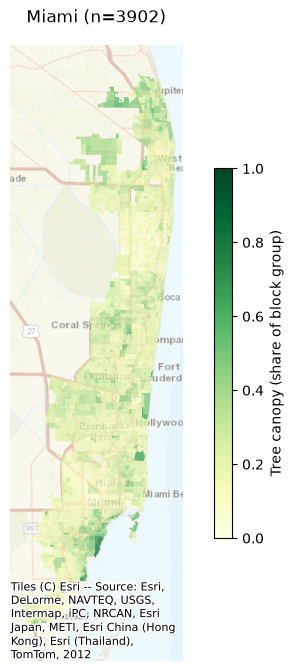

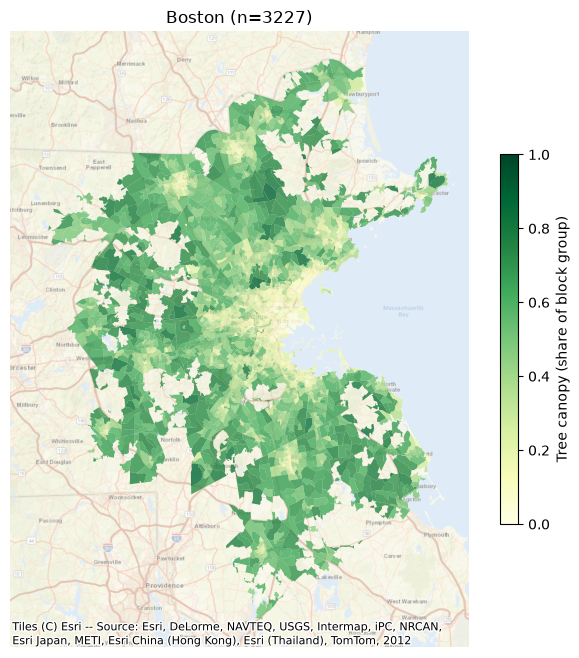

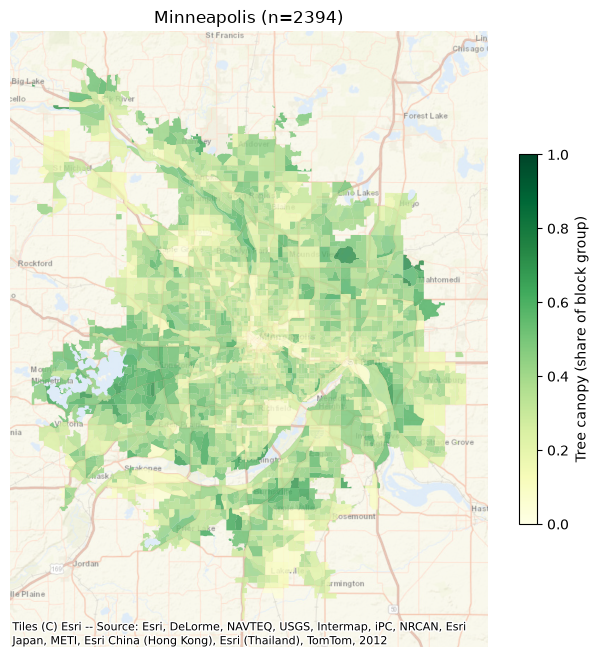

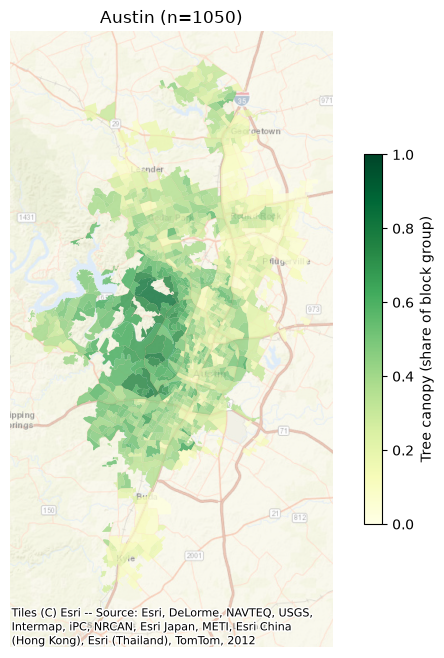

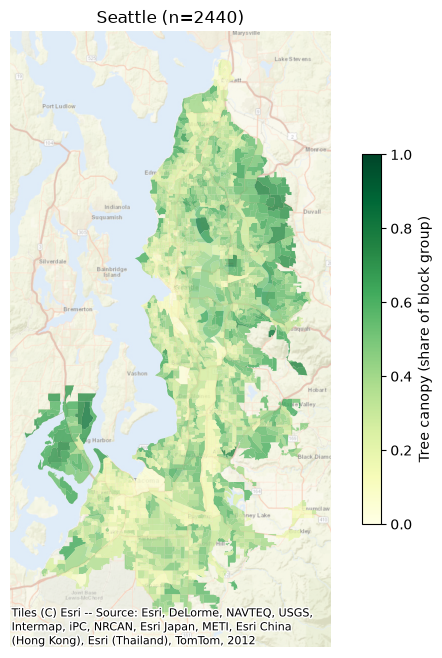

In [44]:
# Visualize geospatial data

df = df.to_crs(3857)  # projected CRS for contextilyso shapes aren't stretched

for city in df['city'].unique():
    sub = df[df['city'] == city]

    fig, ax = plt.subplots(figsize=(8, 8))
    sub.plot(
        column='treecanopy',
        cmap='YlGn',
        vmin=0, vmax=1,
        linewidth=0,
        alpha=0.8,
        legend=True,
        legend_kwds={'label': 'Tree canopy (share of block group)', 'shrink': 0.6},
        ax=ax,
    )
    cx.add_basemap(ax, source=cx.providers.Esri.WorldStreetMap, alpha=0.5)
    ax.set_title(f"{city} (n={len(sub)})")
    ax.axis('off')
    plt.show()